# Other losses and other targets: robust and logistic regression

After this block you can use robust regression (Huber and quantile regression) for data with outliers and explain what each loss estimates. You can fit and interpret a logistic regression for a binary outcome, read its coefficients as log-odds and odds ratios, fit it with statsmodels and scikit-learn, use the scikit-learn pattern that every model follows, and turn predicted probabilities into classes.

Two running questions: **what does a typical Berlin listing cost, when a few asking prices are extreme?** and **which IBM Telco customers are likely to cancel?**

## Teaching map

The **core path** is taught live in 45 minutes. Subsections marked *(depth: self-study or if time allows)* are skipped in class and read at home.

| Section | Core min | Core path | Depth subsections |
|---|---|---|---|
| 1 · Robust regression: Huber | 7 | squared versus Huber loss; OLS and Huber on Berlin prices | loss and weight functions; ε; RLM weights; M-estimators and robust scale; leverage, RANSAC and Theil–Sen |
| 2 · Robust regression: quantile regression | 7 | median and 90th-percentile lines for a host | the pinball loss; `QuantileRegressor`; effects across quantiles |
| 3 · Logistic regression: from a linear model to probabilities | 5 | the sigmoid; Telco churn | why not a straight line; a decision boundary |
| 4 · Log-odds and the interpretation of coefficients | 6 | odds, log-odds, odds ratios | odds ratios in probabilities |
| 5 · Fitting with statsmodels and scikit-learn | 6 | the same model in both libraries | log-loss by hand; the statsmodels report; the GLM view; penalty and scale |
| 6 · The scikit-learn pattern | 6 | estimator, `fit`, `predict`, `score`, `transform`, pipelines | transformers step by step; scaling and the solver |
| 7 · A first look at predicted classes | 4 | thresholds, accuracy against the majority baseline, confusion counts | training versus test accuracy |
| Worked example · Whom should the retention team call? | 4 | ranking by probability; two typical customers | |
| **Theory total** | **45** | then exercises (30) and debrief (15) | |

```mermaid
flowchart LR
    L["least squares:<br/>mean"] --> H["Huber:<br/>large errors count less"]
    L --> Q["quantile:<br/>median, 90th percentile"]
    L --> G["logistic:<br/>yes/no target, probabilities"]
    G --> P["fit / predict / score<br/>pipelines"] --> C["threshold:<br/>predicted classes"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

All imports of the block. `statsmodels.api` (`sm`) holds the robust and generalised linear models; the rest is scikit-learn.

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.compose import ColumnTransformer
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import (HuberRegressor, LinearRegression, LogisticRegression,
                                  QuantileRegressor, RANSACRegressor, TheilSenRegressor)
from sklearn.metrics import confusion_matrix, log_loss, mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

Next we rebuild the price data of block 1: short-stay listings, the distance to Alexanderplatz and the same 80/20 split with `random_state=42`.

In [3]:
listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
short = listings.loc[listings["price"].notna() & listings["minimum_nights"].lt(28)].copy()
short["km_to_centre"] = 111.2 * np.hypot(short["latitude"] - 52.5219,
                                         (short["longitude"] - 13.4132) * np.cos(np.radians(52.52)))
train, test = train_test_split(short, test_size=0.2, random_state=42)
features = ["accommodates", "km_to_centre"]
print(len(train), "training and", len(test), "test listings")

5360 training and 1341 test listings


## 1 · Robust regression: Huber

Least squares squares every residual, so a miss of 10 weighs 100 times as much as a miss of 1. A few gross errors (typing errors, a price entered per week instead of per night, a placeholder such as €9,999) can then pull the whole line towards them. Think of the average income in a café: when a billionaire walks in, the average jumps, the median hardly moves.

**Huber regression** changes the loss. Residuals smaller than a threshold ε (measured in units of a robust estimate of the spread; scikit-learn's default ε = 1.35) are squared as in least squares; larger residuals count only linearly. A point 10 units away then weighs about 10 times, not 100 times, as much as a point 1 unit away. The line follows the bulk of the data.

![Eight gross errors at large x tilt the least-squares line; the Huber line follows the bulk of the data](../figures/robust-vs-ols.png)

The **breakdown point** of an estimator is the share of arbitrary outliers it tolerates before it can be moved arbitrarily far. It is 0 % for least squares: one point is enough.

Next we rebuild the figure: 80 points on a line with slope 0.5, then the 8 points with the largest x get gross errors. `HuberRegressor().fit(X, y)` follows the same pattern as `LinearRegression`; both store the slope in `coef_`.

**Predict before running:** which slope will least squares find, more or less than 0.5?

In [4]:
rng = np.random.default_rng(0)
x = rng.uniform(0, 10, 80)
y = 2 + 0.5 * x + rng.normal(0, 0.5, 80)      # true slope 0.5
bad = np.argsort(x)[-8:]                      # the 8 points with the largest x ...
y[bad] -= rng.uniform(6, 9, 8)                # ... get gross errors
X = x.reshape(-1, 1)
print("least squares slope:", round(LinearRegression().fit(X, y).coef_[0], 2))
print("Huber slope:        ", round(HuberRegressor().fit(X, y).coef_[0], 2))

least squares slope: 0.07
Huber slope:         0.41


The Huber slope is close to the truth but not equal: with ε = 1.35 the outliers keep some influence. That is the price of a smooth compromise.

### Loss and weight functions *(depth: self-study or if time allows)*

*Adapted from [M-Estimators for Robust Linear Modeling](extras/11-statsmodels-m-estimators.ipynb) (statsmodels examples, BSD-3-Clause).*

A robust regression of this family is an **M-estimator**: it minimises the sum of ρ(residual / s), where ρ is a loss function and s a robust estimate of the spread. It is fitted by **iteratively reweighted least squares**: fit, give each row a weight that shrinks with the size of its residual, fit again with these weights, repeat. The weight functions show how each estimator treats large residuals:

- **least squares**: weight 1 everywhere;
- **Huber's T**: weight 1 up to the threshold t, then t / |r|, falling slowly;
- **Tukey's biweight**: weights fall smoothly to exactly 0 beyond c, so very large residuals are ignored completely.

Next we plot the three weight functions. `sm.robust.norms.HuberT(t=1.345).weights(r)` evaluates the weight at residuals `r`.

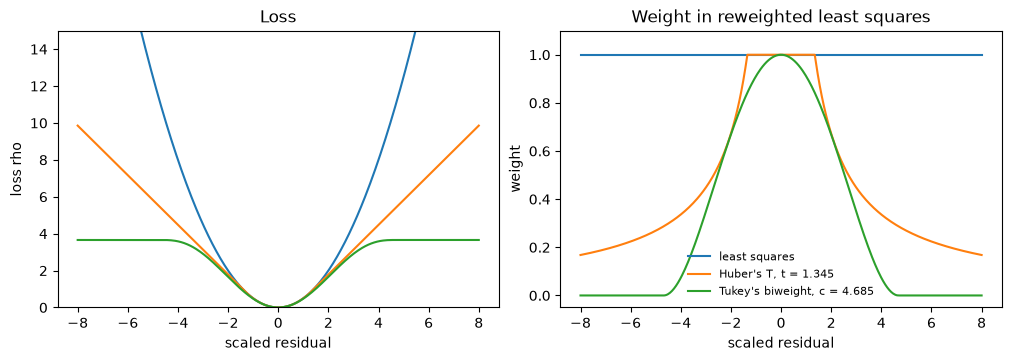

In [5]:
norms = sm.robust.norms
r = np.linspace(-8, 8, 400)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for name, norm in [("least squares", norms.LeastSquares()), ("Huber's T, t = 1.345", norms.HuberT(t=1.345)),
                   ("Tukey's biweight, c = 4.685", norms.TukeyBiweight(c=4.685))]:
    axs[0].plot(r, norm.rho(r), label=name)
    axs[1].plot(r, norm.weights(r), label=name)
axs[0].set(ylim=(0, 15), xlabel="scaled residual", ylabel="loss rho", title="Loss")
axs[1].set(ylim=(-0.05, 1.1), xlabel="scaled residual", ylabel="weight", title="Weight in reweighted least squares")
axs[1].legend(frameon=False, fontsize=8)
plt.show()

### How ε moves the Huber fit *(depth: self-study or if time allows)*

*Code adapted from [HuberRegressor vs Ridge on dataset with strong outliers](extras/08-huber-vs-ridge.ipynb) (scikit-learn gallery, BSD-3-Clause); the unpenalised `Ridge(alpha=0)` of the original is written here as `LinearRegression()`, which is the same model.*

The smaller ε, the earlier residuals switch from squared to linear, and the more robust the fit. As ε grows, Huber regression approaches least squares. The gallery example builds 20 points on a line and adds four strong outliers, two at each end.

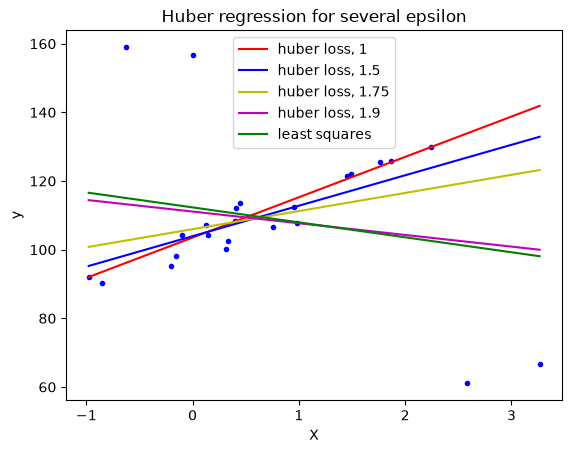

In [6]:
from sklearn.datasets import make_regression

rng = np.random.RandomState(0)
Xh, yh = make_regression(n_samples=20, n_features=1, random_state=0, noise=4.0, bias=100.0)
X_out, y_out = rng.normal(0, 0.5, size=(4, 1)), rng.normal(0, 2.0, size=4)
X_out[:2, :] += Xh.max() + Xh.mean() / 4.0
X_out[2:, :] += Xh.min() - Xh.mean() / 4.0
y_out[:2] += yh.min() - yh.mean() / 4.0
y_out[2:] += yh.max() + yh.mean() / 4.0
Xh, yh = np.vstack((Xh, X_out)), np.concatenate((yh, y_out))
line = np.linspace(Xh.min(), Xh.max(), 7)
plt.plot(Xh, yh, "b.")
for eps, style in zip([1, 1.5, 1.75, 1.9], ["r-", "b-", "y-", "m-"]):
    hub = HuberRegressor(alpha=0.0, epsilon=eps).fit(Xh, yh)
    plt.plot(line, hub.coef_ * line + hub.intercept_, style, label=f"huber loss, {eps}")
ols = LinearRegression().fit(Xh, yh)
plt.plot(line, ols.coef_ * line + ols.intercept_, "g-", label="least squares")
plt.title("Huber regression for several epsilon"); plt.xlabel("X"); plt.ylabel("y"); plt.legend(loc=0)
plt.show()

**On the Berlin prices.** The listings contain real gross errors or near-errors. Next we print the five highest asking prices in the training set. `.nlargest(5, "price")` returns the five rows with the highest price.

In [7]:
train.nlargest(5, "price")[["price", "room_type", "accommodates", "km_to_centre", "district"]].round(1)

,price,room_type,accommodates,km_to_centre,district
8434,10025.0,Entire home/apt,7,14.5,Steglitz - Zehlendorf
12710,7999.2,Entire home/apt,5,15.6,Spandau
517,2956.0,Entire home/apt,15,3.4,Friedrichshain-Kreuzberg
10772,2296.0,Entire home/apt,16,21.1,Treptow - Köpenick
11253,2270.4,Entire home/apt,12,22.4,Treptow - Köpenick


A house for five and a loft for seven guests ask about €8,000 and €10,000 a night, about 15 km from the centre. Session 4 flagged them: they may be typing errors or prices meant to block bookings. Other high prices are plausible (large houses and houseboats for 12 to 16 guests).

Next we fit the price **in euros** (not on the log scale, so that the extreme prices act fully) on guests and distance with least squares, least squares without prices above €1,000, and Huber. `smf.ols(formula, data)` fits least squares from a formula; `HuberRegressor(max_iter=1000)` gets more iterations because prices in euros are on a large scale.

In [8]:
formula = "price ~ accommodates + km_to_centre"
ols_fit = smf.ols(formula, data=train).fit()
ols_trim = smf.ols(formula, data=train.loc[train["price"] < 1000]).fit()
huber = HuberRegressor(max_iter=1000).fit(train[features], train["price"])
rows = []
for name, params, pred in [
    ("least squares", ols_fit.params.to_numpy(), ols_fit.predict(test)),
    ("least squares, prices < 1,000", ols_trim.params.to_numpy(), ols_trim.predict(test)),
    ("Huber", np.r_[huber.intercept_, huber.coef_], huber.predict(test[features]))]:
    rows.append({"model": name, "intercept": params[0], "per guest": params[1], "per km": params[2],
                 "test MAE": mean_absolute_error(test["price"], pred)})
pd.DataFrame(rows).set_index("model").round(2)

,intercept,per guest,per km,test MAE
model,,,,
least squares,59.59,38.34,-0.61,70.68
"least squares, prices < 1,000",93.66,30.85,-3.59,66.89
Huber,81.36,30.60,-3.37,65.52


The extreme prices flatten the least-squares distance effect to well under €1 per km: in the least-squares world, location hardly matters. Huber and least squares without the prices above €1,000 agree that a night costs about €3.40 to €3.60 less per kilometre from Alexanderplatz and about €31 more per guest. The robust fit also predicts the test listings better (lower MAE).

### Which listings does a robust fit down-weight? *(depth: self-study or if time allows)*

*Adapted from [Robust Linear Models](extras/10-statsmodels-robust-models-intro.ipynb) (statsmodels examples, BSD-3-Clause).*

statsmodels fits the same kind of model with `smf.rlm(formula, data, M=sm.robust.norms.HuberT())` and reports the final **weight** of each row: 1 means full weight, values near 0 mean the row was treated as an outlier. It also gives standard errors, which `HuberRegressor` does not. The two implementations use different robust scale estimates, so their coefficients differ slightly.

Next we fit the robust model and list the five training listings with the lowest weights.

In [9]:
rlm_fit = smf.rlm(formula, data=train, M=sm.robust.norms.HuberT()).fit()
print(rlm_fit.params.round(2).to_dict())
weights = pd.Series(rlm_fit.weights, index=train.index, name="weight")
train.join(weights).nsmallest(5, "weight")[["price", "accommodates", "km_to_centre", "weight"]].round(3)

{'Intercept': 85.28, 'accommodates': 30.49, 'km_to_centre': -3.5}


,price,accommodates,km_to_centre,weight
8434,10025.0,7,14.497,0.008
12710,7999.2,5,15.604,0.010
517,2956.0,15,3.370,0.034
11253,2270.4,12,22.427,0.043
10772,2296.0,16,21.074,0.045


The two extreme asking prices get weights of about 1 % of a normal listing. Down-weighting is a modelling decision: inspect the rows with low weights and ask whether they are errors or the most important cases (fraud, failures, unusual products). Report both fits when the conclusion depends on them.

### Robust estimates of centre and spread *(depth: self-study or if time allows)*

*Adapted from [M-Estimators for Robust Linear Modeling](extras/11-statsmodels-m-estimators.ipynb) (statsmodels examples, BSD-3-Clause).*

The same idea applies to single numbers. The mean and the standard deviation have a breakdown point of 0 %; the median and the **median absolute deviation** (MAD, the median distance to the median) have 50 %. The MAD is scaled by a constant (about 1.4826) so that it estimates the standard deviation for normal data; the **interquartile range** (IQR) can be scaled the same way and tolerates 25 % outliers. Robust regression needs such a robust scale s to decide which residuals are "large".

Next we compare the four numbers on the five values 1, 2, 3, 4, 500 and on the Berlin prices. `sm.robust.scale.mad(x)` and `sm.robust.scale.iqr(x)` return the scaled versions.

In [10]:
for name, v in [("1, 2, 3, 4, 500", np.array([1, 2, 3, 4, 500.0])), ("Berlin prices", short["price"].to_numpy())]:
    print(f"{name:16s} mean {v.mean():8.1f}  median {np.median(v):6.1f}  "
          f"sd {v.std():8.1f}  MAD {sm.robust.scale.mad(v):6.1f}  IQR {sm.robust.scale.iqr(v):6.1f}")

1, 2, 3, 4, 500  mean    102.0  median    3.0  sd    199.0  MAD    1.5  IQR    1.5
Berlin prices    mean    193.7  median  157.0  sd    217.0  MAD   84.5  IQR   92.7


### Leverage points: RANSAC and Theil–Sen *(depth: self-study or if time allows)*

*Code from [Theil-Sen Regression](extras/13-theil-sen.ipynb) (scikit-learn gallery, BSD-3-Clause), unchanged except for layout; text adapted from that example and from [Robust linear estimator fitting](extras/09-robust-fit-compared.ipynb) and [RANSAC](extras/12-ransac.ipynb).*

Huber regression limits the influence of large residuals in **y**. It does not protect against outliers in **x** (leverage points): a group of rows far out on the x-axis can drag the line so close that their residuals are no longer large. Two other estimators help:

- **RANSAC** fits the model on many small random subsets, counts how many rows each fit explains well (inliers), and refits on the largest set of inliers. It copes with a large share of gross errors, but needs a sensible residual threshold.
- **Theil–Sen** takes the median of the slopes through pairs (or small subsets) of points. Its breakdown point is about 29 % for a simple regression; it is slow for large data.

Next, the gallery's second example: 200 points on the line y = 3x + 2, with the last 10 % moved to x = 9.9 and raised by 22.

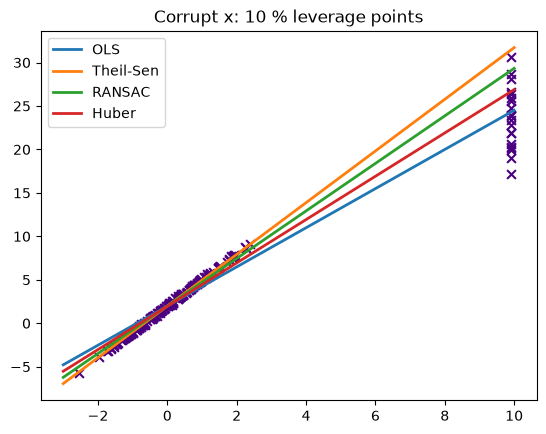

In [11]:
estimators = [("OLS", LinearRegression()), ("Theil-Sen", TheilSenRegressor(random_state=42)),
              ("RANSAC", RANSACRegressor(random_state=42)), ("Huber", HuberRegressor())]
np.random.seed(0)
xs = np.random.randn(200)
ys = 3 * xs + 2 + 0.1 * np.random.randn(200)
xs[-20:] = 9.9
ys[-20:] += 22
plt.scatter(xs, ys, color="indigo", marker="x", s=40)
line_x = np.array([-3, 10])
for name, est in estimators:
    est.fit(xs[:, np.newaxis], ys)
    plt.plot(line_x, est.predict(line_x.reshape(2, 1)), linewidth=2, label=name)
plt.legend(loc="upper left"); plt.title("Corrupt x: 10 % leverage points")
plt.show()

The true line reaches y = 32 at x = 10. Least squares (about 24) and Huber (about 27) are pulled down towards the cluster at x = 9.9; Theil–Sen stays close to the true line and RANSAC lies in between. With a tuned `residual_threshold`, RANSAC would ignore the cluster completely. In the Berlin listings the extreme prices are outliers in y, so Huber is enough there.

> 📖 **Read more:** [extras/08-huber-vs-ridge.ipynb](extras/08-huber-vs-ridge.ipynb), [extras/09-robust-fit-compared.ipynb](extras/09-robust-fit-compared.ipynb), [extras/12-ransac.ipynb](extras/12-ransac.ipynb) and [extras/13-theil-sen.ipynb](extras/13-theil-sen.ipynb) (scikit-learn gallery): the original examples, including five corruption scenarios for OLS, Theil–Sen, RANSAC and Huber.
>
> 📖 **Read more:** [extras/10-statsmodels-robust-models-intro.ipynb](extras/10-statsmodels-robust-models-intro.ipynb) and [extras/11-statsmodels-m-estimators.ipynb](extras/11-statsmodels-m-estimators.ipynb) (statsmodels examples): `RLM` with several norms, outlier tests on Duncan's prestige data, leverage points among stars, and a breakdown experiment.

## 2 · Robust regression: quantile regression

Least squares models the **conditional mean**: the average price for listings with given features. **Quantile regression** models a **conditional quantile** instead. With q = 0.5 it gives the **median** line, which half of the listings lie above and half below; with q = 0.9 the line below which 90 % lie. The median line is robust to outliers in y, and the q = 0.9 line answers a different question: what do the top 10 % of comparable listings charge?

It minimises the **pinball loss**: absolute residuals, weighted by q when the point lies above the line and by 1 − q when it lies below. For q = 0.9, a point above the line costs nine times as much as a point the same distance below, so the line moves up until only 10 % of points lie above it.

Worked example: for the values 1, 2, 3, 4, 100, the mean is 22 and the median 3. A constant fitted by least squares predicts 22; one fitted by median regression predicts 3.

### The pinball loss in code *(depth: self-study or if time allows)*

Next we check that the constant with the lowest pinball loss is the q-quantile. We scan candidate prices for the training listings and compare the minimiser with `np.quantile`.

In [12]:
def pinball(y, c, q):
    diff = y - c
    return np.mean(np.where(diff >= 0, q * diff, (q - 1) * diff))

prices = train["price"].to_numpy()
candidates = np.arange(50, 400, 0.5)
for q in [0.5, 0.9]:
    best = candidates[np.argmin([pinball(prices, c, q) for c in candidates])]
    print(f"q = {q}: lowest pinball loss at {best:.1f} EUR, np.quantile gives {np.quantile(prices, q):.1f} EUR")

q = 0.5: lowest pinball loss at 156.5 EUR, np.quantile gives 156.5 EUR
q = 0.9: lowest pinball loss at 329.5 EUR, np.quantile gives 329.5 EUR


Next, quantile regression on the listings. `smf.quantreg(formula, data).fit(q=0.5)` fits the median line. We also check calibration: the share of test prices below each line should be close to q.

In [13]:
fits = {"least squares (mean)": ols_fit,
        "median (q = 0.5)": smf.quantreg(formula, train).fit(q=0.5),
        "q = 0.9": smf.quantreg(formula, train).fit(q=0.9)}
rows = []
for name, fit in fits.items():
    pred = fit.predict(test)
    rows.append({"model": name, "intercept": fit.params["Intercept"], "per guest": fit.params["accommodates"],
                 "per km": fit.params["km_to_centre"], "test MAE": mean_absolute_error(test["price"], pred),
                 "share of test prices below": np.mean(test["price"] <= pred)})
pd.DataFrame(rows).set_index("model").round(2)

,intercept,per guest,per km,test MAE,share of test prices below
model,,,,,
least squares (mean),59.59,38.34,-0.61,70.68,0.61
median (q = 0.5),76.74,30.69,-3.29,65.47,0.49
q = 0.9,117.34,54.49,-4.64,123.58,0.89


The median line agrees with Huber: about €31 per guest and about €3.30 less per kilometre. Its test MAE is the lowest, as expected, because the median minimises absolute error. The 90th-percentile line is steeper: at the upper end of the market, each guest adds about €54 and each kilometre costs about €4.60. Close to 90 % of the test prices lie below it.

Next we draw the three lines for listings for four guests. `fit.predict(grid)` predicts for a small DataFrame with the same column names.

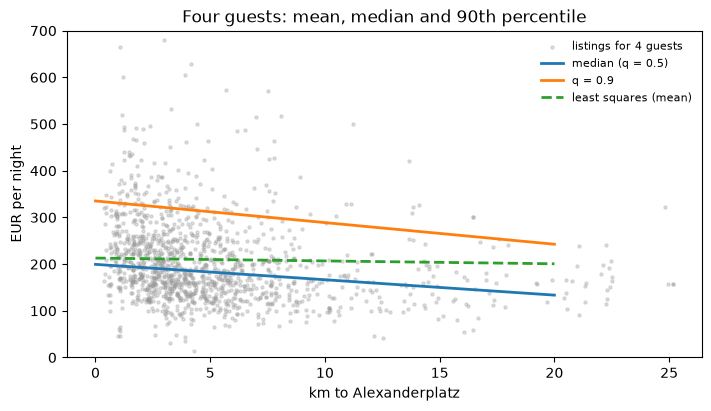

In [14]:
grid = pd.DataFrame({"accommodates": 4, "km_to_centre": np.linspace(0, 20, 50)})
four = short.loc[short["accommodates"] == 4]
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.scatter(four["km_to_centre"], four["price"], s=5, alpha=0.3, color="0.6", label="listings for 4 guests")
for name, style in [("median (q = 0.5)", "-"), ("q = 0.9", "-"), ("least squares (mean)", "--")]:
    ax.plot(grid["km_to_centre"], fits[name].predict(grid), ls=style, lw=2, label=name)
ax.set(ylim=(0, 700), xlabel="km to Alexanderplatz", ylabel="EUR per night",
       title="Four guests: mean, median and 90th percentile")
ax.legend(frameon=False, fontsize=8)
plt.show()

A host with a flat for four guests near the centre can read a typical price from the median line and the price of the better listings nearby from the q = 0.9 line. Correcting or removing confirmed errors (Session 4) remains the right fix; the robust fits show what the data say before the errors are found.

> **Note.** Quantile lines fitted separately can cross (the 0.9 line below the 0.5 line for some x), especially at the edges of the data. Check a plot before reporting them.

### Quantile regression in scikit-learn *(depth: self-study or if time allows)*

*Adapted from [Quantile regression](extras/14-quantile-regression-sklearn.ipynb) (scikit-learn gallery, BSD-3-Clause).*

scikit-learn has `QuantileRegressor(quantile=q, alpha=0)`; `alpha=0` switches off its default penalty. The gallery example makes a point worth checking on our data: the loss a model minimises decides what it predicts. Least squares minimises the MSE and predicts the mean; median regression minimises the MAE and predicts the median. So on the test listings each should win on its own metric.

Next we fit both on the training listings and compare MAE and MSE on the test listings. `solver="highs"` is the fast linear-programming solver.

In [15]:
lin = LinearRegression().fit(train[features], train["price"])
med = QuantileRegressor(quantile=0.5, alpha=0, solver="highs").fit(train[features], train["price"])
for name, m in [("LinearRegression", lin), ("QuantileRegressor, q = 0.5", med)]:
    p = m.predict(test[features])
    print(f"{name:27s} test MAE {mean_absolute_error(test['price'], p):7.1f}   test MSE {mean_squared_error(test['price'], p):9.0f}")

LinearRegression            test MAE    70.7   test MSE     21738
QuantileRegressor, q = 0.5  test MAE    65.5   test MSE     22613


Each model wins on the loss it was trained for. A metric is a choice, and so is a loss.

### How effects change across quantiles *(depth: self-study or if time allows)*

*Adapted from [Quantile regression](extras/15-quantile-regression-statsmodels.ipynb) (statsmodels examples, BSD-3-Clause), which replicates Koenker & Hallock (2001) on Engel's food-expenditure data.*

Fitting many quantiles shows whether a feature shifts the whole price distribution in the same way. If the guest coefficient rises with q, an extra guest adds more at the expensive end than at the cheap end: the spread of prices grows with size (heteroscedasticity). Least squares gives one average number.

Next we fit q = 0.1, 0.2, …, 0.9 and plot the guest coefficient with its 95 % confidence band against the least-squares estimate. `.conf_int().loc["accommodates"]` gives the interval of one coefficient.

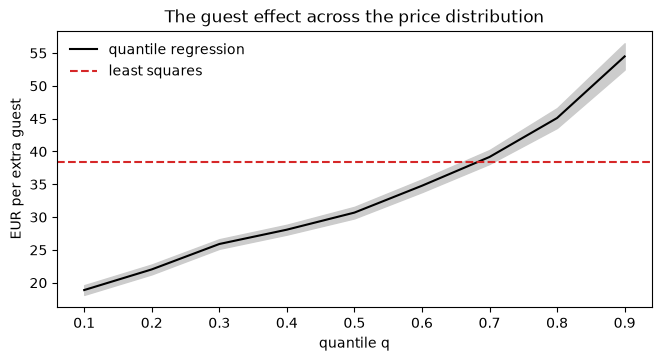

In [16]:
qs = np.arange(0.1, 0.91, 0.1)
qfits = [smf.quantreg(formula, train).fit(q=q, max_iter=5000) for q in qs]
coef = np.array([f.params["accommodates"] for f in qfits])
ci = np.array([f.conf_int().loc["accommodates"].to_numpy() for f in qfits])
fig, ax = plt.subplots(figsize=(6.5, 3.5), layout="constrained")
ax.plot(qs, coef, color="black", label="quantile regression")
ax.fill_between(qs, ci[:, 0], ci[:, 1], color="0.8")
ax.axhline(ols_fit.params["accommodates"], color="tab:red", ls="--", label="least squares")
ax.set(xlabel="quantile q", ylabel="EUR per extra guest", title="The guest effect across the price distribution")
ax.legend(frameon=False)
plt.show()

The guest effect rises steadily, from under €20 per guest at q = 0.1 to about €54 at q = 0.9: an extra guest adds much more at the expensive end of the market. The least-squares number (about €38) sits near the 70th percentile, pulled up by the extreme prices.

> 📖 **Read more:** [extras/14-quantile-regression-sklearn.ipynb](extras/14-quantile-regression-sklearn.ipynb) (scikit-learn gallery): `QuantileRegressor` with heteroscedastic and with asymmetric (Pareto) noise, and the 5 % / 95 % interval.
>
> 📖 **Read more:** [extras/15-quantile-regression-statsmodels.ipynb](extras/15-quantile-regression-statsmodels.ipynb) (statsmodels examples): `QuantReg` on Engel's data, the classic example of Koenker and Bassett (1982).

## 3 · Logistic regression: from a linear model to probabilities

Many targets are not numbers but yes/no outcomes: does a customer cancel, does a listing show a registration number, is a transaction fraudulent? A linear regression on a 0/1 target (the **linear probability model**) can predict values below 0 or above 1, which are not probabilities. **Logistic regression** keeps the weighted sum of linear regression,

z = b₀ + b₁x₁ + … + bₚxₚ,

and passes it through the **sigmoid** (logistic) function p = 1 / (1 + e^(−z)), an S-shaped curve that squeezes any number into the range 0 to 1. σ(0) = 0.5; large positive z gives probabilities close to 1, large negative z close to 0. The curve is steepest at z = 0: a change in z matters most when the outcome is uncertain.

Despite its name, logistic **regression** is a classification model: it models the probability of a class. The name comes from the regression on the log-odds scale (section 4).

![Left: the sigmoid curve with points at z = −2, 0 and 2. Right: predicted churn probability falling with tenure in the Telco data](../figures/sigmoid.png)

The example is the IBM Telco customer-churn sample: 7,043 customers of a telephone and internet provider, with their contract, services, charges and whether they left in the last month (`Churn`).

Next we download the Telco data (about 1 MB) from IBM's GitHub repository and create a 0/1 target. `(series == "Yes").astype(int)` turns text into 0/1; `groupby(...).agg(["mean", "size"])` gives the churn rate per contract type.

In [17]:
url = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
       "master/data/Telco-Customer-Churn.csv")
telco = pd.read_csv(url)
telco["churn"] = (telco["Churn"] == "Yes").astype(int)
print(telco.shape, "churn rate:", round(telco["churn"].mean(), 3))
telco.groupby("Contract")["churn"].agg(["mean", "size"]).round(3)

(7043, 22) churn rate: 0.265


,mean,size
Contract,,
Month-to-month,0.427,3875
One year,0.113,1473
Two year,0.028,1695


Next, the sigmoid in NumPy. `np.exp` works element by element on an array.

**Predict before running:** what is σ(0), and what is σ(−4) roughly?

In [18]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

print(sigmoid(np.array([-4, -2, 0, 2, 4])).round(3))

[0.018 0.119 0.5   0.881 0.982]


### Why not a straight line? *(depth: self-study or if time allows)*

Next we fit both a linear and a logistic model of churn on tenure (months as a customer) and compare their predictions with the observed churn rate per tenure band. `smf.logit(formula, data).fit(disp=0)` fits a logistic regression quietly; `pd.cut` makes the bands.

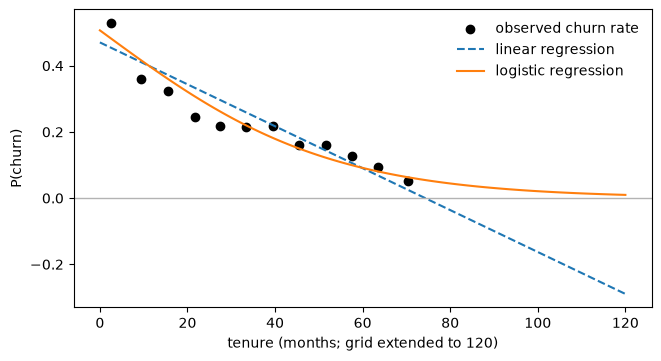

linear model at 72 and 120 months: [0.014, -0.29]


In [19]:
lpm = smf.ols("churn ~ tenure", data=telco).fit()
logit_t = smf.logit("churn ~ tenure", data=telco).fit(disp=0)
grid_t = pd.DataFrame({"tenure": np.arange(0, 121)})
bands = telco.groupby(pd.cut(telco["tenure"], range(0, 80, 6), include_lowest=True), observed=True)
observed = bands.agg(tenure=("tenure", "mean"), rate=("churn", "mean"))
fig, ax = plt.subplots(figsize=(6.5, 3.5), layout="constrained")
ax.scatter(observed["tenure"], observed["rate"], color="black", label="observed churn rate")
ax.plot(grid_t["tenure"], lpm.predict(grid_t), "--", label="linear regression")
ax.plot(grid_t["tenure"], logit_t.predict(grid_t), label="logistic regression")
ax.axhline(0, color="0.7", lw=1)
ax.set(xlabel="tenure (months; grid extended to 120)", ylabel="P(churn)")
ax.legend(frameon=False)
plt.show()
print("linear model at 72 and 120 months:", lpm.predict(pd.DataFrame({"tenure": [72, 120]})).round(3).tolist())

The straight line falls below zero for long-standing customers, an impossible probability; the logistic curve flattens towards zero and follows the observed rates more closely.

### A decision boundary in two features *(depth: self-study or if time allows)*

*Adapted from [Linear models for classification](extras/16-logistic-regression.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0), with the penguins replaced by Telco customers.*

With two features, the rule "predict churn when p > 0.5" is the same as "predict churn when z > 0", and z = b₀ + b₁x₁ + b₂x₂ = 0 is a straight line in the plane: the **decision boundary**. Logistic regression is a *linear* classifier. Colouring the plane by the predicted probability shows how confident the model is: pale near the boundary, dark far from it.

Next we fit a pipeline on tenure and monthly charges and draw the probabilities with `DecisionBoundaryDisplay.from_estimator(model, X, response_method="predict_proba")`, with 400 customers on top. Pipelines and `StandardScaler` are explained in section 6.

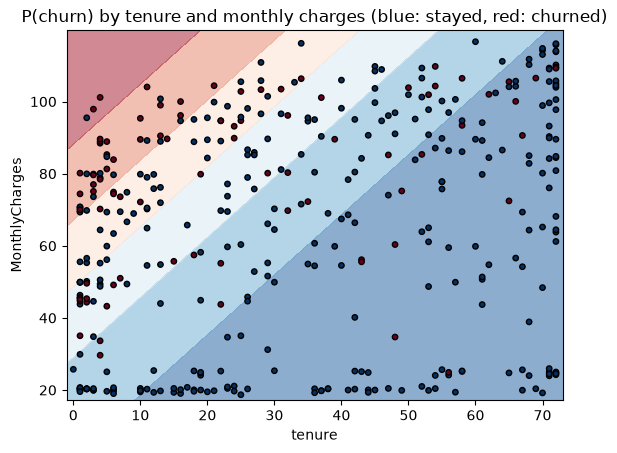

tenure           -1.344
MonthlyCharges    0.989
dtype: float64


In [20]:
two = ["tenure", "MonthlyCharges"]
clf2 = make_pipeline(StandardScaler(), LogisticRegression()).fit(telco[two], telco["churn"])
sample = telco.sample(400, random_state=0)
disp = DecisionBoundaryDisplay.from_estimator(clf2, telco[two], response_method="predict_proba",
                                              cmap="RdBu_r", alpha=0.5)
disp.ax_.scatter(sample["tenure"], sample["MonthlyCharges"], c=sample["churn"], cmap="RdBu_r",
                 edgecolor="k", s=15)
disp.ax_.set_title("P(churn) by tenure and monthly charges (blue: stayed, red: churned)")
plt.show()
print(pd.Series(clf2[-1].coef_[0], index=two).round(3))

The boundary is a straight, oblique line: both coefficients are non-zero. New customers with high monthly charges (top left) have the highest churn probability.

> **Note.** `predict_proba` gives estimates. A classifier can be accurate on average and still over- or under-confident for some groups; Session 8 checks this with calibration plots.

> 📖 **Read more:** [extras/16-logistic-regression.ipynb](extras/16-logistic-regression.ipynb) (INRIA scikit-learn MOOC): logistic regression on two penguin species, the boundary equation, coefficients as a bar chart and `predict_proba`.

## 4 · Log-odds and the interpretation of coefficients

Betting shops quote **odds**: the chance of the event against the chance of no event, odds = p / (1 − p). A probability of 0.8 means odds of 0.8 / 0.2 = 4 ("4 to 1"); p = 0.5 means odds of 1.

The **log-odds** (logit) is log(p / (1 − p)). Solving the sigmoid for z shows that z **is** the log-odds:

log(p / (1 − p)) = b₀ + b₁x₁ + … + bₚxₚ.

So logistic regression is a linear model for the log-odds. A coefficient bⱼ has three readings:

- bⱼ is the change in **log-odds** per one-unit increase of xⱼ, with the other features held fixed;
- e^bⱼ is the **odds ratio**: the factor by which the odds are multiplied per unit increase;
- the effect on the **probability** is not constant: it depends on where on the sigmoid the customer is.

Next we convert some probabilities into odds and log-odds. Note that log-odds are symmetric around 0: p = 0.1 and p = 0.9 give −2.2 and +2.2.

In [21]:
p = np.array([0.1, 0.5, 0.8, 0.9])
odds = p / (1 - p)
pd.DataFrame({"p": p, "odds": odds, "log-odds": np.log(odds)}).round(2)

,p,odds,log-odds
0,0.1,0.11,-2.20
1,0.5,1.00,0.00
2,0.8,4.00,1.39
3,0.9,9.00,2.20


Next we read the tenure coefficient of the one-feature model of section 3. `np.exp(b)` is the odds ratio per month, `np.exp(12 * b)` per year.

**Predict before running:** the coefficient is negative. Is the odds ratio above or below 1?

In [22]:
b = logit_t.params["tenure"]
print(f"coefficient {b:.4f}  odds ratio per month {np.exp(b):.3f}  per year {np.exp(12 * b):.2f}")

coefficient -0.0388  odds ratio per month 0.962  per year 0.63


Each extra month multiplies the odds of churn by about 0.96, a 4 % reduction; twelve extra months multiply them by about 0.6.

> **Note.** An odds ratio is not a risk ratio. With a baseline churn probability of 40 %, an odds ratio of 2 raises it to 57 %, not to 80 %. Translate odds ratios into probabilities for a few typical customers before you report them.

### Odds ratios in probabilities *(depth: self-study or if time allows)*

The same odds ratio moves the probability by different amounts depending on the starting point. New odds = old odds × OR; then p = odds / (1 + odds).

Next we apply an odds ratio of 2 to five baseline probabilities.

In [23]:
base = np.array([0.02, 0.1, 0.4, 0.6, 0.9])
new_odds = base / (1 - base) * 2
pd.DataFrame({"baseline p": base, "p after OR = 2": new_odds / (1 + new_odds),
              "p doubled (wrong)": np.minimum(2 * base, 1)}).round(3)

,baseline p,p after OR = 2,p doubled (wrong)
0,0.02,0.039,0.04
1,0.10,0.182,0.20
2,0.40,0.571,0.80
3,0.60,0.750,1.00
4,0.90,0.947,1.00


For rare events (2 %) an odds ratio of 2 almost doubles the probability, which is why odds ratios approximate risk ratios in studies of rare diseases. For common events the two diverge strongly.

## 5 · Fitting with statsmodels and scikit-learn

Logistic regression has no closed formula like least squares. Its coefficients are chosen by **maximum likelihood**: the values under which the observed outcomes are most probable. Equivalently they minimise the **log-loss** (cross-entropy): for each customer, −log of the probability the model gave to what actually happened. A churner predicted at p = 0.9 costs −log 0.9 ≈ 0.1; a churner predicted at p = 0.1 costs −log 0.1 ≈ 2.3. The software finds the minimum step by step.

The two libraries answer different questions about the same model:

- **statsmodels** (`smf.logit`) is the statistical view: coefficients with standard errors, confidence intervals and p-values; formula syntax with `C()` for categories. Question: which effects are reliable?
- **scikit-learn** (`LogisticRegression`) is the prediction view: pipelines, `predict_proba`, `predict`. Question: how well does it predict new customers? It adds an L2 **penalty** by default (`C=1.0`), which shrinks the coefficients a little; `C=np.inf` switches it off. Penalties are the subject of Session 7.

Next we split the customers 75/25. `stratify=telco["churn"]` keeps the churn rate equal in both parts.

In [24]:
tr, te = train_test_split(telco, test_size=0.25, stratify=telco["churn"], random_state=0)
print(len(tr), "training and", len(te), "test customers; churn rate", round(tr["churn"].mean(), 3),
      "and", round(te["churn"].mean(), 3))

5282 training and 1761 test customers; churn rate 0.265 and 0.265


### Log-loss by hand *(depth: self-study or if time allows)*

Next we compute the log-loss of two models on the test customers: one that gives every customer the training churn rate, and the tenure model. `sklearn.metrics.log_loss(y_true, p)` does the same as the formula in the first line.

In [25]:
def my_log_loss(y, p):
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

p_const = np.full(len(te), tr["churn"].mean())
p_tenure = smf.logit("churn ~ tenure", data=tr).fit(disp=0).predict(te)
print("constant rate:", round(my_log_loss(te["churn"], p_const), 4), round(log_loss(te["churn"], p_const), 4))
print("tenure model: ", round(my_log_loss(te["churn"], p_tenure), 4))

constant rate: 0.5784 0.5784
tenure model:  0.5042


Next, the full model in statsmodels: tenure, monthly charges, senior citizen, contract, internet service, payment method and paperless billing. We build a table of odds ratios with 95 % confidence intervals by exponentiating the coefficients and their interval bounds.

In [26]:
formula_c = ("churn ~ tenure + MonthlyCharges + SeniorCitizen + C(Contract) + C(InternetService)"
             " + C(PaymentMethod) + C(PaperlessBilling)")
logit = smf.logit(formula_c, data=tr).fit(disp=0)
ci = logit.conf_int()
pd.DataFrame({"coef (log-odds)": logit.params, "odds ratio": np.exp(logit.params),
              "OR low": np.exp(ci[0]), "OR high": np.exp(ci[1]), "p": logit.pvalues}).round(3)

,coef (log-odds),odds ratio,OR low,OR high,p
Intercept,-0.799,0.450,0.299,0.676,0.000
C(Contract)[T.One year],-0.791,0.453,0.357,0.576,0.000
C(Contract)[T.Two year],-1.449,0.235,0.160,0.345,0.000
C(InternetService)[T.Fiber optic],0.959,2.608,1.941,3.504,0.000
C(InternetService)[T.No],-0.774,0.461,0.328,0.648,0.000
C(PaymentMethod)[T.Credit card (automatic)],-0.040,0.961,0.746,1.238,0.759
C(PaymentMethod)[T.Electronic check],0.423,1.526,1.234,1.887,0.000
C(PaymentMethod)[T.Mailed check],-0.043,0.958,0.743,1.236,0.741
C(PaperlessBilling)[T.Yes],0.447,1.563,1.323,1.847,0.000
tenure,-0.032,0.969,0.964,0.973,0.000


Reading, with the other features held fixed (reference: month-to-month contract, DSL, bank transfer, no paperless billing):

- a two-year contract multiplies the odds of churn by about 0.23 compared with month-to-month; a one-year contract by about 0.45;
- fibre-optic internet multiplies them by about 2.6 compared with DSL;
- paying by electronic check multiplies them by about 1.5 compared with bank transfer;
- each month of tenure multiplies them by about 0.97;
- monthly charges add little once the internet service is known (the two features overlap).

### The statsmodels report *(depth: self-study or if time allows)*

*Adapted from [ISLP Lab 4, Classification](extras/19-islp-classification-lab.ipynb) (ISLP labs, BSD-2-Clause).*

Beyond the coefficient table, `.summary()` reports the number of observations, the **pseudo R²** (McFadden's: 1 − log-likelihood of the model / log-likelihood of a constant model; values of 0.2 to 0.4 already indicate a good fit, it is not comparable to the R² of linear regression) and the **LLR p-value**, a test of the whole model against the constant model. Logistic regression is also a **generalised linear model** (GLM) with a binomial family and a logit link; ISLP fits it with `sm.GLM(..., family=sm.families.Binomial())`, and the coefficients are identical.

Next we print the key numbers and refit the model as a GLM. `smf.glm(formula, data, family=sm.families.Binomial())` is the formula version.

In [27]:
print("observations:", int(logit.nobs), " pseudo R2:", round(logit.prsquared, 3), " LLR p-value:", logit.llr_pvalue)
glm = smf.glm(formula_c, data=tr, family=sm.families.Binomial()).fit()
print("largest difference between Logit and GLM coefficients:", float(np.abs(glm.params - logit.params).max()))

observations: 5282  pseudo R2: 0.269  LLR p-value: 0.0
largest difference between Logit and GLM coefficients: 9.103828801926284e-15


Next, the same model in scikit-learn. scikit-learn needs numbers, so the categories are one-hot encoded with `drop="first"` (the first category becomes the reference, as in statsmodels). `ColumnTransformer` applies the encoder to the categorical columns and passes the numeric ones through (section 6 explains it); `C=np.inf` switches the penalty off. `get_feature_names_out()` names the resulting columns; a dictionary comprehension translates the statsmodels names (`C(Contract)[T.One year]`) into the scikit-learn ones (`cat__Contract_One year`) so the two columns line up.

In [28]:
numeric = ["tenure", "MonthlyCharges", "SeniorCitizen"]
categorical = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling"]
pre_ref = ColumnTransformer([("num", "passthrough", numeric),
                             ("cat", OneHotEncoder(drop="first"), categorical)])
sk = make_pipeline(pre_ref, LogisticRegression(C=np.inf, max_iter=5000)).fit(tr, tr["churn"])
sk_coef = pd.Series(sk[-1].coef_[0], index=sk[0].get_feature_names_out())
sm_names = {n: ("cat__" + n[2:].replace(")[T.", "_").rstrip("]") if n.startswith("C(") else "num__" + n)
            for n in logit.params.index[1:]}
sm_coef = logit.params.iloc[1:].rename(sm_names)
pd.DataFrame({"scikit-learn": sk_coef, "statsmodels": sm_coef}).round(3)

,scikit-learn,statsmodels
cat__Contract_One year,-0.793,-0.791
cat__Contract_Two year,-1.451,-1.449
cat__InternetService_Fiber optic,0.961,0.959
cat__InternetService_No,-0.777,-0.774
cat__PaperlessBilling_Yes,0.447,0.447
cat__PaymentMethod_Credit card (automatic),-0.046,-0.040
cat__PaymentMethod_Electronic check,0.417,0.423
cat__PaymentMethod_Mailed check,-0.049,-0.043
num__MonthlyCharges,0.000,0.001
num__SeniorCitizen,0.351,0.352


Without a penalty the coefficients match statsmodels up to the precision of the numerical optimiser.

### Penalty and scale *(depth: self-study or if time allows)*

*Adapted from [Preprocessing for numerical features](extras/18-scaling-in-pipelines.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

With the default penalty (`C=1.0`), the coefficients depend on the units of the features: a feature measured in cents would be penalised differently from the same feature in euros. Standardising the numeric features (mean 0, standard deviation 1) makes the penalty treat them alike. Scaling also helps the numerical solver: it reaches the minimum in fewer **iterations** (`n_iter_`). If the solver hits `max_iter` before converging, scale the data before raising `max_iter`.

Next we fit the default `LogisticRegression` with and without standardised numeric features and compare the iterations and the test accuracy.

In [29]:
pre_raw = ColumnTransformer([("num", "passthrough", numeric), ("cat", OneHotEncoder(drop="first"), categorical)])
pre_std = ColumnTransformer([("num", StandardScaler(), numeric), ("cat", OneHotEncoder(drop="first"), categorical)])
for name, pre in [("unscaled", pre_raw), ("standardised", pre_std)]:
    m = make_pipeline(pre, LogisticRegression(max_iter=5000))
    start = time.perf_counter()
    m.fit(tr, tr["churn"])
    print(f"{name:13s} iterations {m[-1].n_iter_[0]:4d}  test accuracy {m.score(te, te['churn']):.3f}"
          f"  fit time {time.perf_counter() - start:.3f} s")

unscaled      iterations  177  test accuracy 0.791  fit time 0.029 s


standardised  iterations   19  test accuracy 0.790  fit time 0.015 s


> 📖 **Read more:** [extras/19-islp-classification-lab.ipynb](extras/19-islp-classification-lab.ipynb) (ISLP labs): logistic regression as a GLM on stock-market data, predictions turned into a confusion table, and a test on a later year; its sections on LDA, QDA, naive Bayes and k-NN go beyond this session.

## 6 · The scikit-learn pattern: fit, predict, score, transform, pipelines

*Text adapted from [First model with scikit-learn](extras/17-first-model-fit-predict-score.ipynb) and [Preprocessing for numerical features](extras/18-scaling-in-pipelines.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0); diagrams from the same course.*

Every model in scikit-learn, from linear regression to random forests, follows one pattern. Learn it once and every later model is a change of one line.

- An **estimator** is any object with a `fit` method. `fit` combines a **learning algorithm** with **model states**: it takes the training data (and target) and sets the states.
- A **predictor** is an estimator with `predict`: classifiers and regressors. Classifiers add `predict_proba`.
- A **transformer** is an estimator with `transform`: scalers, encoders. It changes data instead of predicting.
- `score(X, y)` predicts and compares with the truth: R² for regressors, accuracy for classifiers.

Settings you choose are **hyperparameters**, passed to the constructor: `LogisticRegression(C=1.0)`. What the model learns from data is stored in attributes ending in an underscore: `coef_`, `intercept_`, `classes_`, `mean_`.

![fit: the learning algorithm takes the training data and target and sets the model states](extras/figures/api_diagram-predictor.fit.svg)

![predict: the prediction function uses the model states and new data](extras/figures/api_diagram-predictor.predict.svg)

![score: predict, then compare the predictions with the true target](extras/figures/api_diagram-predictor.score.svg)

Next, the four steps on the churn data with numeric features only: construct, fit, predict, score. `get_params()` lists the hyperparameters.

In [30]:
X_tr, X_te = tr[numeric], te[numeric]
y_tr, y_te = tr["churn"], te["churn"]
clf = LogisticRegression(max_iter=1000)        # 1. construct: hyperparameters only
clf.fit(X_tr, y_tr)                            # 2. fit: learn the model states
print(clf.predict(X_te.head(5)))               # 3. predict: classes for new rows
print(round(clf.score(X_te, y_te), 3))         # 4. score: accuracy on the test rows
print(clf.get_params()["C"], clf.classes_, clf.coef_.round(3))

[0 0 0 0 0]
0.792
1.0 [0 1] [[-0.055  0.031  0.668]]


### Transformers step by step *(depth: self-study or if time allows)*

*Adapted from [Preprocessing for numerical features](extras/18-scaling-in-pipelines.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

`StandardScaler` learns the mean and standard deviation of each column in `fit` (its model states `mean_` and `scale_`) and applies (x − mean) / sd in `transform`. The `fit` of a transformer takes only X, no target. `fit_transform` does both in one call. **Fit on the training rows only**, then transform training and test rows with what was learned; otherwise the test rows leak into the preprocessing (Session 7). `set_output(transform="pandas")` keeps column names.

![Transformer fit](extras/figures/api_diagram-transformer.fit.svg)

![Transformer transform](extras/figures/api_diagram-transformer.transform.svg)

![Transformer fit_transform](extras/figures/api_diagram-transformer.fit_transform.svg)

Next we fit a scaler on the training customers and transform the test customers.

In [31]:
scaler = StandardScaler().set_output(transform="pandas")
scaler.fit(X_tr)
print("means:", scaler.mean_.round(2), " sds:", scaler.scale_.round(2))
scaler.transform(X_te).describe().loc[["mean", "std"]].round(2)

means: [32.13 64.34  0.17]  sds: [24.46 30.12  0.37]


,tenure,MonthlyCharges,SeniorCitizen
mean,0.04,0.06,-0.03
std,1.02,1.00,0.97


The test columns have means close to, but not exactly, 0: they were scaled with the training statistics, as they should be.

**Pipelines.** A pipeline chains transformers and a final predictor: `make_pipeline(StandardScaler(), LogisticRegression())`. `fit` calls `fit_transform` on each transformer and then `fit` on the predictor; `predict` calls `transform` on each transformer and then `predict`. A pipeline is itself an estimator, so it has `fit`, `predict`, `predict_proba` and `score`, and the "fit only on training rows" rule becomes automatic. `make_pipeline` names the steps after their classes; `pipe.named_steps` lists them and `pipe[-1]` is the last step.

![Pipeline fit](extras/figures/api_diagram-pipeline.fit.svg)

![Pipeline predict](extras/figures/api_diagram-pipeline.predict.svg)

A **ColumnTransformer** applies different transformers to different columns (scaling to numbers, one-hot encoding to categories) and puts the results side by side. `handle_unknown="ignore"` lets the encoder cope with a category that appears only in new data.

Next we build the churn model as one pipeline and use it like any model.

In [32]:
preprocess = ColumnTransformer([("num", StandardScaler(), numeric),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)])
pipe = make_pipeline(preprocess, LogisticRegression(max_iter=1000))
pipe.fit(tr, y_tr)
print(list(pipe.named_steps))
print("test accuracy:", round(pipe.score(te, y_te), 3))

['columntransformer', 'logisticregression']
test accuracy: 0.79


**The same code, other models.** Because every estimator shares the pattern, swapping the model changes one line. The loop below fits three very different classifiers with identical code: logistic regression, *k*-nearest neighbours (Session 8) and a decision tree (Session 10).

**Predict before running:** will the three test accuracies be far apart or close?

In [33]:
for model in [LogisticRegression(max_iter=1000), KNeighborsClassifier(n_neighbors=25),
              DecisionTreeClassifier(max_depth=4, random_state=0)]:
    p_ = make_pipeline(preprocess, model).fit(tr, y_tr)
    print(f"{type(model).__name__:24s} test accuracy {p_.score(te, y_te):.3f}")

LogisticRegression       test accuracy 0.790
KNeighborsClassifier     test accuracy 0.781


DecisionTreeClassifier   test accuracy 0.794


> 📖 **Read more:** [extras/17-first-model-fit-predict-score.ipynb](extras/17-first-model-fit-predict-score.ipynb) (INRIA scikit-learn MOOC): the pattern with a *k*-nearest-neighbours classifier on the adult census data, and why the training score is optimistic.
>
> 📖 **Read more:** [extras/18-scaling-in-pipelines.ipynb](extras/18-scaling-in-pipelines.ipynb) (INRIA scikit-learn MOOC): scaling, `set_output`, pipelines and solver iterations on the adult census data.

## 7 · A first look at predicted classes

`predict_proba` returns one column per class, in the order of `classes_`; for churn, column 1 is the probability of churn. `predict` turns it into a class with a **threshold** of 0.5: churn if p > 0.5.

**Accuracy** is the share of correct predictions. Always compare it with the **majority baseline**: predicting the most common class for everyone. In the Telco data, "nobody churns" is right for about 73.5 % of customers.

A **confusion matrix** counts the four combinations of true and predicted class: true negatives (stayers predicted to stay), false positives (stayers flagged as churners, false alarms), false negatives (churners missed) and true positives (churners found). Lowering the threshold finds more churners at the cost of more false alarms. Which threshold is right depends on what each error costs (Session 8).

Next we take the churn probabilities of the pipeline, compare accuracy with the baseline and count the four outcomes at three thresholds. `confusion_matrix(y_true, y_pred).ravel()` returns TN, FP, FN, TP in that order.

In [34]:
p_churn = pipe.predict_proba(te)[:, 1]
print("classes:", pipe.classes_, " majority baseline accuracy:", round(1 - y_te.mean(), 3))
rows = []
for threshold in [0.5, 0.3, 0.2]:
    pred = (p_churn > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    rows.append({"threshold": threshold, "accuracy": (pred == y_te).mean(), "TP (found)": tp,
                 "FN (missed)": fn, "FP (false alarms)": fp, "TN": tn})
pd.DataFrame(rows).set_index("threshold").round(3)

classes: [0 1]  majority baseline accuracy: 0.735


,accuracy,TP (found),FN (missed),FP (false alarms),TN
threshold,,,,,
0.5,0.790,236,231,138,1156
0.3,0.752,346,121,316,978
0.2,0.706,398,69,448,846


At 0.5 the model is right for 79 % of customers, 5.5 points above the baseline, and finds 236 of the 467 churners, about half. Lower thresholds find many more churners while accuracy falls: accuracy alone hides which errors a model makes.

### Training versus test accuracy *(depth: self-study or if time allows)*

*Adapted from [ISLP Lab 4](extras/19-islp-classification-lab.ipynb) (ISLP labs, BSD-2-Clause).*

As in regression, accuracy on the training rows is optimistic. ISLP makes the point with stock-market data, where a model that looks slightly better than chance on its training days does worse than chance on a later year. A confusion table with labels makes the counts easier to read; `pd.crosstab(predicted, true)` builds one.

In [35]:
print("training accuracy:", round(pipe.score(tr, y_tr), 3), " test accuracy:", round(pipe.score(te, y_te), 3))
pd.crosstab(pd.Series(pipe.predict(te), name="predicted"), pd.Series(y_te.to_numpy(), name="true"))

training accuracy: 0.8  test accuracy: 0.79


true,0,1
predicted,,
0,1156,231
1,138,236


Here the gap is small: a model with a dozen coefficients and over 5,000 training customers has little room to overfit.

> **Note.** Accuracy misleads on imbalanced data. When only 1 % of cases are positive, "always negative" has 99 % accuracy and is useless. Session 8 introduces precision, recall, ROC curves and class imbalance.

## Worked example · Whom should the retention team call?

A retention team can call 500 of the 1,761 test customers this month. Calling at random would reach about 26.5 % churners, the base rate. Ranking customers by predicted churn probability should do much better.

Next we sort the test customers by `p_churn` and count the churners among the top 500. `np.argsort(-p)` gives the positions from the highest probability down.

In [36]:
order = np.argsort(-p_churn)
top500 = y_te.to_numpy()[order[:500]]
print(f"churners among the top 500: {top500.sum()} ({top500.mean():.1%}); "
      f"expected at random: {500 * y_te.mean():.0f} ({y_te.mean():.1%})")

churners among the top 500: 291 (58.2%); expected at random: 133 (26.5%)


Next we translate the model into probabilities for two typical customers who differ only in their contract: three months of tenure, €80 a month, fibre optic, electronic check, paperless billing. The statsmodels `logit.predict(df)` takes a DataFrame with the original columns.

In [37]:
typical = pd.DataFrame({
    "tenure": [3, 3], "MonthlyCharges": [80, 80], "SeniorCitizen": [0, 0],
    "Contract": ["Month-to-month", "Two year"], "InternetService": ["Fiber optic", "Fiber optic"],
    "PaymentMethod": ["Electronic check", "Electronic check"], "PaperlessBilling": ["Yes", "Yes"],
})
typical.assign(p_churn=logit.predict(typical).round(3))[["Contract", "p_churn"]]

,Contract,p_churn
0,Month-to-month,0.726
1,Two year,0.384


The two-year contract multiplies the odds by about 0.23, which here lowers the probability from about 73 % to about 38 %: a large drop, but far from "a quarter of the risk". This is the translation a manager needs, and the ranking above is what the retention team uses.

## Check your understanding

1. What does the Huber loss do with a residual of 10 compared with least squares, and why does that protect the fit?
2. About which share of the test prices should lie below the line of a quantile regression with q = 0.9, and how do you check it?
3. A logistic coefficient for fibre optic is 0.96. What is the odds ratio, and why is it not "2.6 times as likely"?
4. What does `C=np.inf` change in scikit-learn's `LogisticRegression`, and why does it make the coefficients equal to statsmodels'?
5. The churn model has 79 % accuracy. Why is this number not enough to judge it?

## Exercises (30 min)

Work in pairs; one types, the other directs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. The code exercises reuse `short`, `train`, `test`, `listings`, `telco`, `tr`, `te` and `pipe` from above, so run the notebook first.

### 2.1 · One number for everyone

*Paper · 5 min*

> You must predict one price for all listings. Which number minimises the MAE, and which the MSE?

*Source:* [Median, Wikipedia](https://en.wikipedia.org/wiki/Median)

*Your answer:*

### 2.2 · Log-odds in your head

*Paper · 5 min*

> A logistic coefficient of 0.69 means what for the odds?

*Source:* [UCLA OARC: odds ratios in logistic regression](https://stats.oarc.ucla.edu/other/mult-pkg/faq/general/faq-how-do-i-interpret-odds-ratios-in-logistic-regression/)

*Your answer:*

### 2.3 · Which line fails?

*Predict · 5 min*

> Write down for each line whether it runs or raises an error, and which error. Then run them, one per cell.
>
> 1. `LinearRegression().predict(short[["accommodates"]])`
> 2. `LinearRegression().fit(short["accommodates"], short["price"])`
> 3. `StandardScaler().fit_transform(short[["room_type"]])`
> 4. `LinearRegression().fit(short[["accommodates"]], short["price"]).coef_`

*Source:* original exercise for this course

*Your answer:*

### 2.4 · The same five lines, a model you have not seen

*Code · 10 min*

> Pick a regressor that this block did not use, for example `GradientBoostingRegressor` (`sklearn.ensemble`) or `SVR` (`sklearn.svm`), and look up its hyperparameters in its docstring. Split `X = short[["accommodates", "km_to_centre"]]` and `y = np.log(short["price"])` 80/20 with `random_state=42`, then run the pattern of section 6: construct, fit, predict three rows, score on the test data. Which learned attributes (ending in `_`) does your model have? Then wrap it in `make_pipeline(StandardScaler(), ...)`: does the test R² change, and why or why not?

*Source:* original exercise for this course

### 2.5 · Perfect separation

*Predict, then Code · 10 min*

> Fit a logistic regression where every customer older than 50 churned and no one younger did. What happens to the age coefficient?

*Source:* [Separation (statistics), Wikipedia](https://en.wikipedia.org/wiki/Separation_(statistics))

*Your answer:*

### 2.6 · How wide is the price range for a given size?

*Code · 15 min*

> For the entire homes in `short`, fit quantile regressions of the price in euros on `accommodates` for q = 0.1, 0.5 and 0.9, and least squares for comparison. Predict the three quantiles for a flat for two and for six guests. How does the range between the 10th and the 90th percentile change with size, and what would you tell a host with a flat for six guests?

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

### 2.7 · Who shows a registration number?

*Code · 15 min*

> Take all entire homes and private rooms in `listings` (with or without a price). Fit a logistic regression of "the licence field holds a registration number" (`license_status == "registration number"`) on room type, a multi-listing host indicator (`calculated_host_listings_count > 1`) and `accommodates`. Report the odds ratios with their 95 % confidence intervals and interpret the coefficient of the multi-listing host indicator in one sentence. Why would adding the hotel rooms cause trouble (see exercise 2.5)?

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

### 2.8 · What does a missed churner cost?

*Code · 10 min*

> A retention call costs €10; a customer who leaves costs €200 of margin. Assume a call always keeps a churner. Using the churn probabilities of `pipe` on the test customers, compute the total cost 10 × (TP + FP) + 200 × FN for thresholds from 0.05 to 0.95 in steps of 0.05. Which threshold is cheapest, and how does its cost compare with calling nobody and with calling everybody?

*Source:* original exercise for this course (IBM Telco case study)

### 2.9 · Huber's ε

*Code · 10 min*

*Stretch:*

> Fit `HuberRegressor` of the price in euros on `accommodates` and `km_to_centre` on `train` for ε = 1.1, 1.35, 2, 5 and 20, and least squares for comparison. How does the coefficient per km change as ε grows, and why?

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

## Debrief (15 min)

- **Compare** two interpretations of the multi-listing host coefficient (2.7) and two cost curves (2.8). Did both pairs find the same cheapest threshold?
- **Look for** an odds ratio read as a change in probability ("three times as likely"), a quantile line read as a prediction for every listing (2.6), and a threshold chosen on accuracy instead of cost.
- **Typical mistake:** forgetting that `predict_proba` returns two columns, or reading column 0 as the churn probability.
- **Bridge to Session 7:** every comparison today used one train–test split. Session 7 makes the estimates reliable with cross-validation, adds regularisation (the `C` of logistic regression) and tunes it. The team project starts from baselines: the most frequent heading and a simple rule.

## Further reading

- James, G., Witten, D., Hastie, T., Tibshirani, R. & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*, chapter 4 (classification, logistic regression) with Lab 4. Springer. <https://www.statlearning.com/>
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras and TensorFlow*, 3rd ed., chapter 4 (logistic regression). O'Reilly.
- Huber, P. J. & Ronchetti, E. M. (2009). *Robust Statistics*, 2nd ed. Wiley.
- Koenker, R. & Hallock, K. F. (2001). Quantile regression. *Journal of Economic Perspectives*, 15(4), 143–156. <https://doi.org/10.1257/jep.15.4.143>
- Gelman, A., Hill, J. & Vehtari, A. (2020). *Regression and Other Stories*, chapters 13–14 (logistic regression). Cambridge University Press. <https://avehtari.github.io/ROS-Examples/>
- INRIA (2024). *scikit-learn MOOC*, modules "The predictive modeling pipeline" and "Linear models" (CC BY 4.0). <https://inria.github.io/scikit-learn-mooc/>
- Buitinck, L. et al. (2013). API design for machine learning software: experiences from the scikit-learn project. <https://arxiv.org/abs/1309.0238>
- Data: Inside Airbnb, Berlin, snapshot of 26 June 2026 (CC BY 4.0), <https://insideairbnb.com/get-the-data/>; IBM, *Telco customer churn* sample data (Apache-2.0), <https://github.com/IBM/telco-customer-churn-on-icp4d>
- Extras of this block: [08](extras/08-huber-vs-ridge.ipynb) to [19](extras/19-islp-classification-lab.ipynb); provenance and licences in [extras/README.md](extras/README.md).